In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
file_path = "ObesityDataSet_raw_and_data_sinthetic.csv"
df = pd.read_csv(file_path)

# 1. Display basic info


In [4]:
# 1. Display basic info
print('\n--- Dataset Info ---')
print(df.info())
len(df)


--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   str    
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   str    
 12  FAF                    

2111

# 2. Data Cleaning


In [6]:
# 2. Data Cleaning
print('\n--- Cleaning Data ---')
print(f'Initial row count: {len(df)}')
df_example = df.drop_duplicates()
print(f'Row count after cleaning: {len(df_example)}')
#the result show that there are duplicates in the dataset, so we will remove them.
df = df.drop_duplicates()
len(df)



--- Cleaning Data ---
Initial row count: 2111
Row count after cleaning: 2087


2087

# 3. Categorical Encodings


In [8]:
# 3. Categorical Encodings
print('\n--- Encoding Categorical Variables ---')

# Binary columns: map each value explicitly so 1 always means "yes"/"Male"
df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})
for col in ['family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC']:
    df[col] = df[col].map({'no': 0, 'yes': 1})

# Ordinal mapping for frequency columns
ordinal_mapping = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}
for col in ['CAEC', 'CALC']:
    df[col] = df[col].map(ordinal_mapping)

# One-Hot Encoding for nominal features (e.g., MTRANS)
df = pd.get_dummies(df, columns=['MTRANS'], drop_first=True, dtype=int)


# Label Encoding for the target variable (NObeyesdad)
# Target classes in order from lightest to heaviest
target_order = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I',
                'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II',
                'Obesity_Type_III']
df['NObeyesdad'] = df['NObeyesdad'].map({name: i for i, name in enumerate(target_order)})

print(df.head())
print('Missing values after encoding:', df.isnull().sum().sum())


--- Encoding Categorical Variables ---
   Gender   Age  Height  Weight  family_history_with_overweight  FAVC  FCVC  \
0       0  21.0    1.62    64.0                               1     0   2.0   
1       0  21.0    1.52    56.0                               1     0   3.0   
2       1  23.0    1.80    77.0                               1     0   2.0   
3       1  27.0    1.80    87.0                               0     0   3.0   
4       1  22.0    1.78    89.8                               0     0   2.0   

   NCP  CAEC  SMOKE  CH2O  SCC  FAF  TUE  CALC  NObeyesdad  MTRANS_Bike  \
0  3.0     1      0   2.0    0  0.0  1.0     0           1            0   
1  3.0     1      1   3.0    1  3.0  0.0     1           1            0   
2  3.0     1      0   2.0    0  2.0  1.0     2           1            0   
3  3.0     1      0   2.0    0  2.0  0.0     2           2            0   
4  1.0     1      0   2.0    0  0.0  0.0     1           3            0   

   MTRANS_Motorbike  MTRANS_Public

# 4. Feature Scaling 


In [10]:
# 4. Feature Scaling 
#train/test split
print('\n-- Splitting and Scaling ---')

X = df.drop(columns='NObeyesdad')
y = df['NObeyesdad']

#stratified 80/20 data split to keep class proportions in each set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

#Fit scaler on training data only then apply to both sets (scaler now learns average only from train data)
numerical_cols = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
scaler = StandardScaler()
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print('Train size:', X_train.shape, ' Test size:', X_test.shape)
print('Train class counts:\n', y_train.value_counts().sort_index())


-- Splitting and Scaling ---
Train size: (1669, 19)  Test size: (418, 19)
Train class counts:
 NObeyesdad
0    214
1    225
2    221
3    232
4    281
5    237
6    259
Name: count, dtype: int64


# 5. Exploratory Data Analysis & Visualizations



--- Generating Visualizations ---


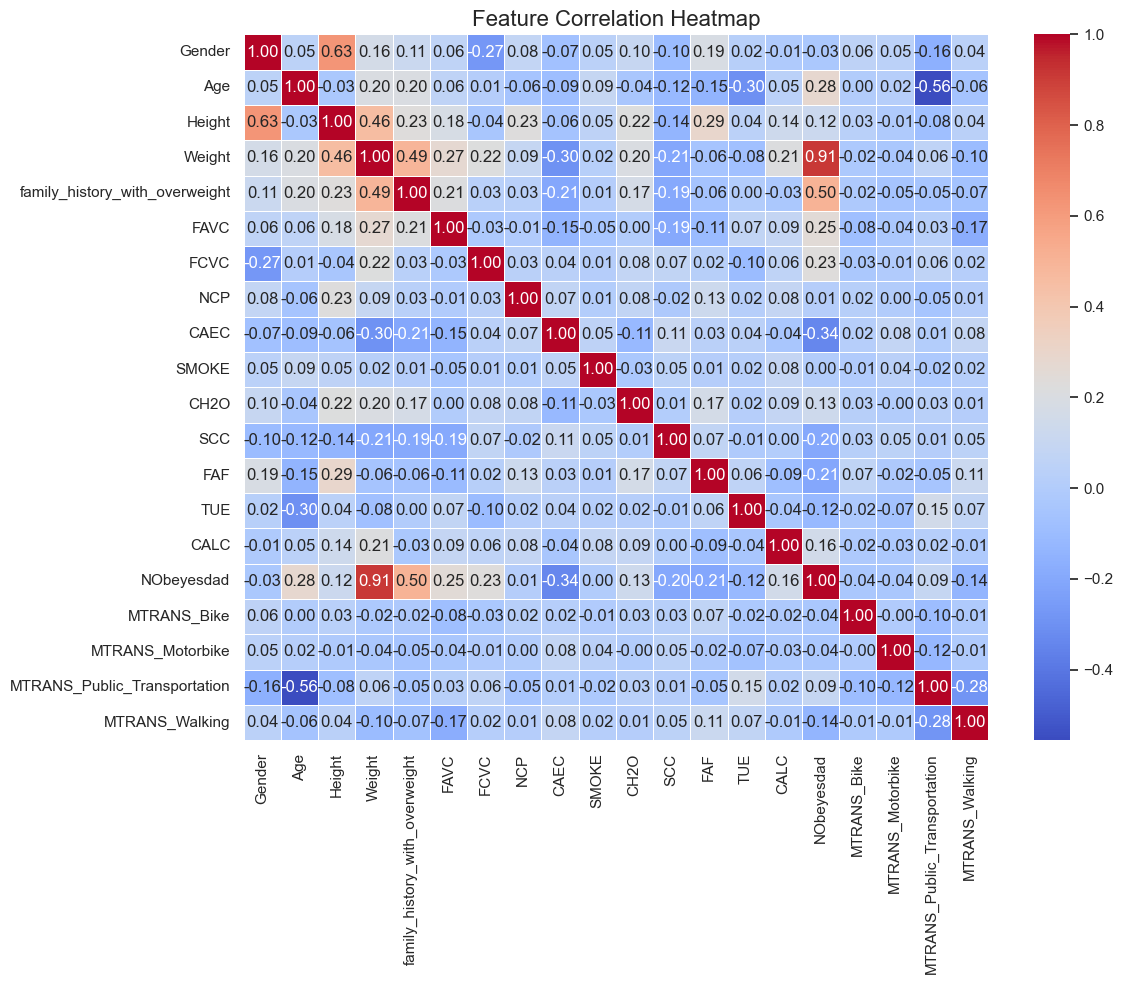

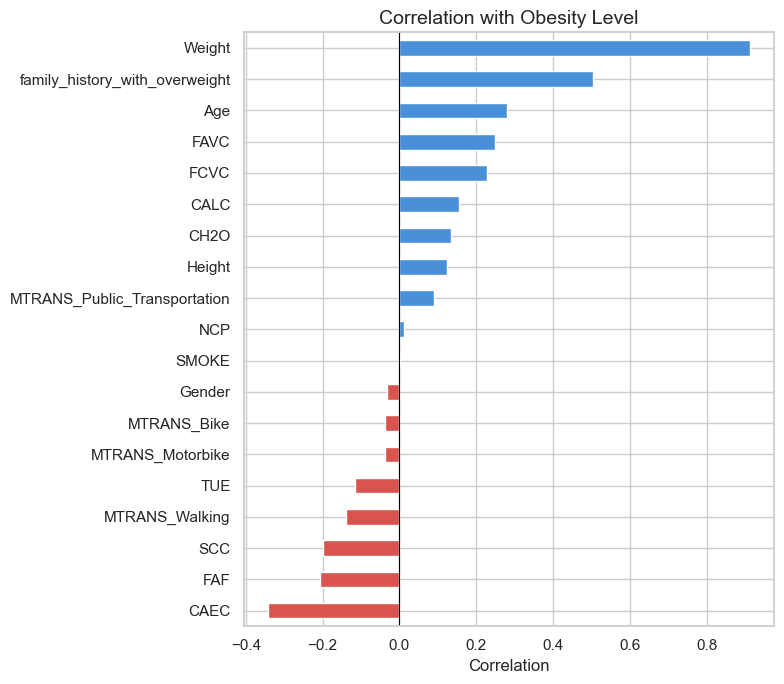

In [25]:
# 5. Exploratory Data Analysis & Visualizations
print('\n--- Generating Visualizations ---')
sns.set_theme(style='whitegrid')

# Figure 1: Correlation Heatmap
plt.figure(figsize=(12, 10))
numeric_df = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr()
sns.heatmap(
    correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5
)
plt.title('Feature Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

# Figure 1b: Correlation of each feature with obesity level
target_corr = correlation_matrix['NObeyesdad'].drop('NObeyesdad').sort_values()
plt.figure(figsize=(8, 7))
target_corr.plot(kind='barh', color=['#d9534f' if v < 0 else '#4a90d9' for v in target_corr])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation with Obesity Level', fontsize=14)
plt.xlabel('Correlation')
plt.tight_layout()
plt.show()

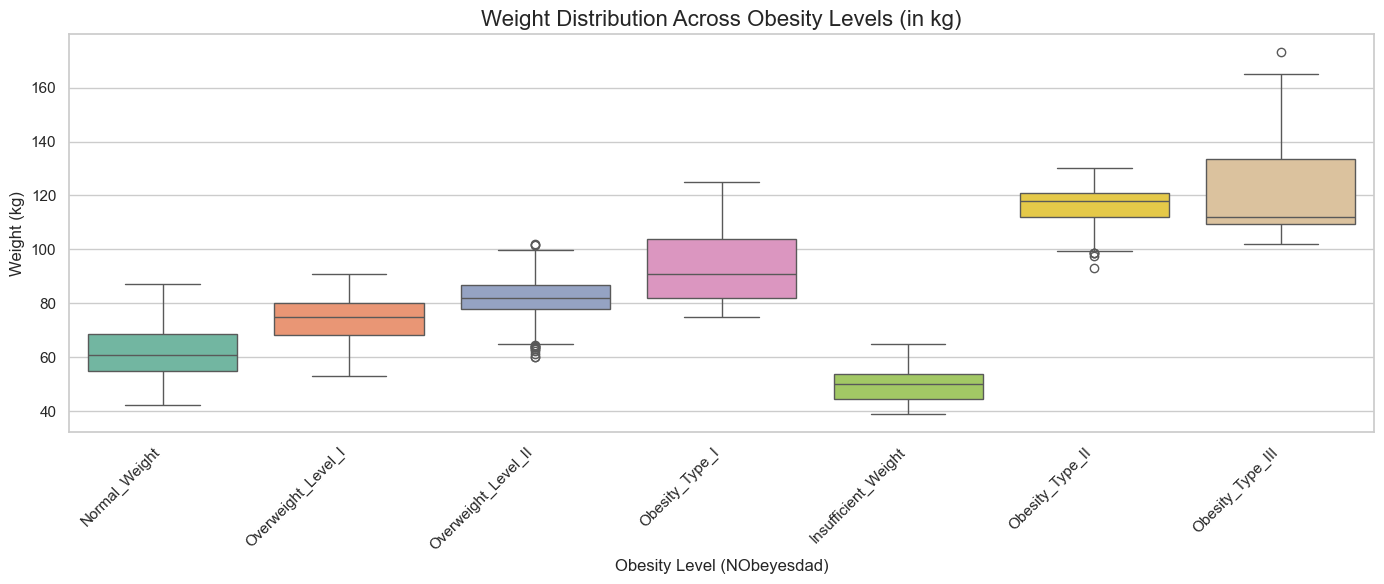

In [13]:
# Figure 2: Weight vs Target Distribution (Boxplot using raw data)
plt.figure(figsize=(14, 6))

df_raw = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

sns.boxplot(
    x='NObeyesdad', y='Weight', data=df_raw, palette='Set2', hue='NObeyesdad', legend=False
)

plt.xticks(rotation=45, ha='right')
plt.title('Weight Distribution Across Obesity Levels (in kg)', fontsize=16)
plt.xlabel('Obesity Level (NObeyesdad)', fontsize=12)
plt.ylabel('Weight (kg)', fontsize=12)
plt.tight_layout()
plt.show()

/var/folders/00/y0mgjfy10_751kmk7rr46frc0000gn/T/ipykernel_57617/2925582823.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='NObeyesdad', data=df_raw, palette='Set1', order=['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III'])


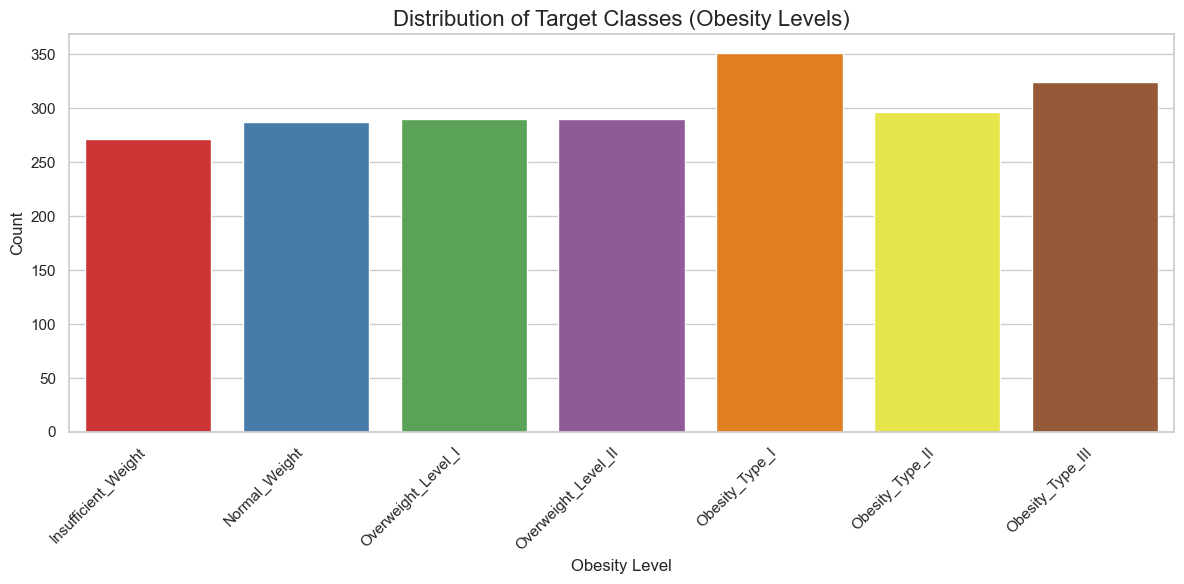

In [14]:
#Figure 3: Distribution of Target Classes (Countplot using raw data)
plt.figure(figsize=(12, 6))
sns.countplot(x='NObeyesdad', data=df_raw, palette='Set1', order=['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III'])
plt.xticks(rotation=45, ha='right')
plt.title('Distribution of Target Classes (Obesity Levels)', fontsize=16)
plt.xlabel('Obesity Level', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.tight_layout()

plt.show()

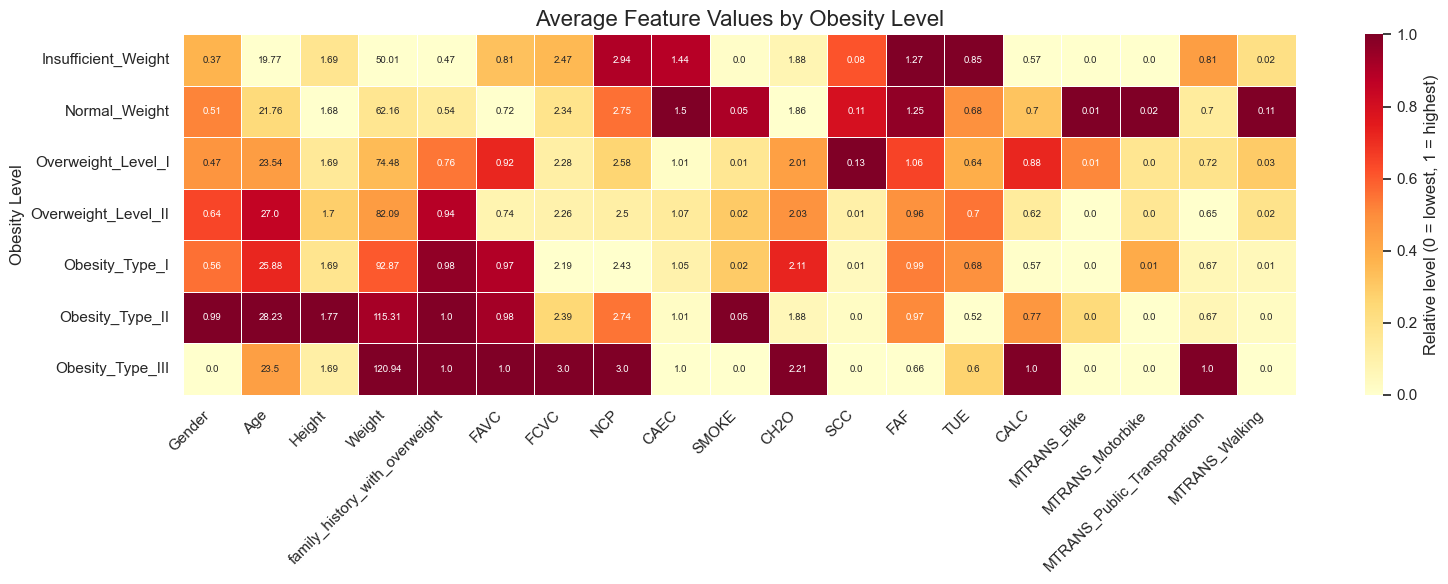

In [29]:
# Figure4: Average feature value for each obesity level (The numbers are the real averages, for example Gender 0.99 means 99% male. The colors show which level has the highest value for that column.)
level_means = df.groupby('NObeyesdad').mean()
level_means.index = target_order          # show names instead of 0-6 for each level

# Scale each column 0-1 so features with different units can share one color scale
level_norm = (level_means - level_means.min()) / (level_means.max() - level_means.min())

plt.figure(figsize=(16, 6))
sns.heatmap(level_norm, annot=level_means.round(2), fmt='', cmap='YlOrRd',
            linewidths=0.5, annot_kws={'size': 7}, cbar_kws={'label': 'Relative level (0 = lowest, 1 = highest)'})
plt.title('Average Feature Values by Obesity Level', fontsize=16)
plt.ylabel('Obesity Level')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

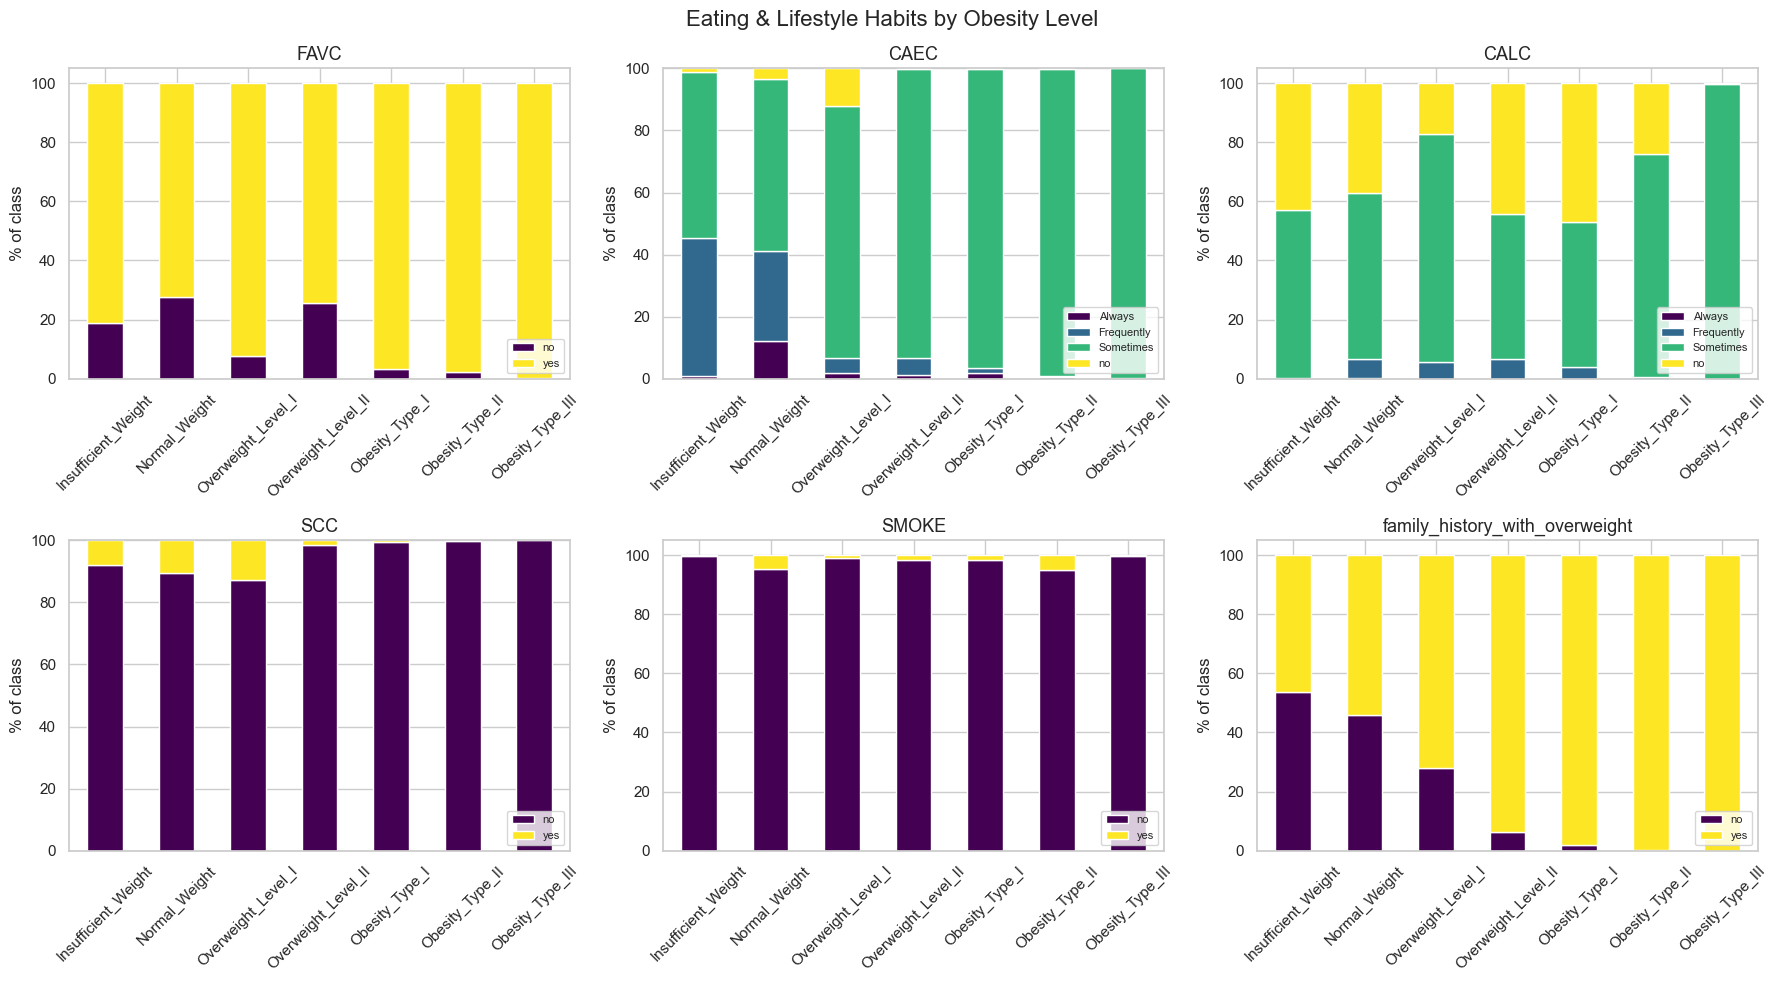

In [31]:
# Figure5: Eating and lifestyle habits across obesity levels
habit_cols = ['FAVC', 'CAEC', 'CALC', 'SCC', 'SMOKE', 'family_history_with_overweight']
order = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I',
         'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flat, habit_cols):
    pct = pd.crosstab(df_raw['NObeyesdad'], df_raw[col], normalize='index').loc[order] * 100
    pct.plot(kind='bar', stacked=True, ax=ax, colormap='viridis', legend=True)
    ax.set_title(col, fontsize=13)
    ax.set_xlabel('')
    ax.set_ylabel('% of class')
    ax.tick_params(axis='x', rotation=45)
    ax.legend(fontsize=8, loc='lower right')
plt.suptitle('Eating & Lifestyle Habits by Obesity Level', fontsize=16)
plt.tight_layout()
plt.show()